# 3.0 - Escolha dos horizontes (cabecas) do modelo

Pergunta: ate quantos minutos no futuro o modelo preve a pluma MELHOR que as referencias simples?

- **Persistencia**: a previsao para t+k e o score da camera agora (P(y_t+k) = P(y_t)).
- **Calendario**: so a hora/dia (climatologia).
- **Modelo base**: tags + calendario.
- **Modelo + estado**: tags + calendario + estado atual da camera.

Metrica: AP por fold do CV temporal (so treino), media dos folds.
Teste (nas cabecas possiveis do config): bootstrap pareado por dias + correcao de Holm. O hold out so e usado no final.
Decisao (indicadora): em cada cabeca usa o modelo so onde ele vence a persistencia; se nao, a persistencia.
O resultado vai para `reports/escolha_horizontes.md` e para `PREVISOR_POR_CABECA` do `config.py`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import PATH_REPORTS, TAGS, CALENDARIO, ESTADO, DIAS_SUSPEITOS, CABECAS_POSSIVEIS, MODELOS
from ml_atmospheric_emission.dataset import load_interim, remove_days
from ml_atmospheric_emission.features import create_datetime_columns, create_target, create_state_columns, create_future_targets
from ml_atmospheric_emission.modeling.evaluate import split_holdout, compare_horizons, choose_horizons, choose_forecaster, holdout_ap, save_horizon_report
from ml_atmospheric_emission.plots import plot_horizons

In [3]:
#True: removes the suspicious days (22h of plume in a row, including the night)
#False: sensitivity analysis with all the days
REMOVER_DIAS_SUSPEITOS = True

ds = load_interim()
ds = create_datetime_columns(ds)
ds = create_target(ds)
if REMOVER_DIAS_SUSPEITOS:
    ds = remove_days(ds, DIAS_SUSPEITOS)
ds = create_state_columns(ds)
dx = create_future_targets(ds, 72)   #72 x 5 min = 6 horas no futuro

#The hold out (last 20% of the period) is separated ONCE
dx_treino, dx_holdout = split_holdout(dx)

Treino ate: 2026-10-02 23:15:00 | linhas treino: 11598 | linhas hold out: 2900


In [4]:
#Models of the config: calendario, base (tags + calendario) and base_estado (tags + calendario + camera state)
modelos = MODELOS
print(modelos)
#Every 5 minutes up to 2 hours, then every 30 minutes up to 6 hours
lista_deslocamentos = list(range(1, 25)) + [30, 36, 42, 48, 54, 60, 66, 72]

{'calendario': ['Hora', 'Minuto', 'Dia_Semana'], 'base': ['306-AIT-004-2', '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4', '406-AIT-001', 'Hora', 'Minuto', 'Dia_Semana'], 'base_estado': ['306-AIT-004-2', '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4', '406-AIT-001', 'Hora', 'Minuto', 'Dia_Semana', 'score_atual', 'score_max_30']}


## 1. CV temporal: AP de cada abordagem e teste contra as referencias

Curva de AP em 32 horizontes; teste estatistico so nas cabecas possiveis (CABECAS_POSSIVEIS). Demora alguns minutos.

In [5]:
tabela_cv = compare_horizons(dx_treino, lista_deslocamentos, modelos, CABECAS_POSSIVEIS, n_boot=1000)

minutos: 5 | AP persistencia: 0.669 | AP modelos: [np.float64(0.179), np.float64(0.163), np.float64(0.674)]
minutos: 10 | AP persistencia: 0.57 | AP modelos: [np.float64(0.176), np.float64(0.187), np.float64(0.593)]
minutos: 15 | AP persistencia: 0.488 | AP modelos: [np.float64(0.174), np.float64(0.176), np.float64(0.498)]
minutos: 20 | AP persistencia: 0.437 | AP modelos: [np.float64(0.175), np.float64(0.178), np.float64(0.448)]
minutos: 25 | AP persistencia: 0.407 | AP modelos: [np.float64(0.179), np.float64(0.178), np.float64(0.409)]
minutos: 30 | AP persistencia: 0.36 | AP modelos: [np.float64(0.179), np.float64(0.173), np.float64(0.35)]
minutos: 35 | AP persistencia: 0.344 | AP modelos: [np.float64(0.181), np.float64(0.186), np.float64(0.35)]
minutos: 40 | AP persistencia: 0.32 | AP modelos: [np.float64(0.177), np.float64(0.189), np.float64(0.307)]
minutos: 45 | AP persistencia: 0.3 | AP modelos: [np.float64(0.173), np.float64(0.191), np.float64(0.299)]
minutos: 50 | AP persistenc

In [6]:
colunas = ['minutos', 'ap_persistencia', 'ap_calendario', 'ap_base', 'ap_base_estado',
           'p_base_vs_persistencia', 'p_base_vs_calendario', 'p_base_estado_vs_persistencia', 'p_base_estado_vs_calendario']
tabela_cv[tabela_cv['minutos'].isin(CABECAS_POSSIVEIS)][colunas].round(3)

,minutos,ap_persistencia,ap_calendario,ap_base,ap_base_estado,p_base_vs_persistencia,p_base_vs_calendario,p_base_estado_vs_persistencia,p_base_estado_vs_calendario
2,15,0.488,0.174,0.176,0.498,1.000,0.577,0.330,0.001
5,30,0.360,0.179,0.173,0.350,1.000,0.668,0.685,0.001
11,60,0.246,0.176,0.189,0.258,0.967,0.374,0.349,0.027
17,90,0.201,0.178,0.177,0.224,0.836,0.618,0.201,0.110
23,120,0.147,0.173,0.134,0.151,0.582,0.864,0.292,0.676
25,180,0.103,0.171,0.175,0.159,0.002,0.373,0.003,0.673
27,240,0.077,0.171,0.172,0.154,0.001,0.434,0.001,0.657
31,360,0.080,0.171,0.151,0.140,0.002,0.813,0.002,0.908


## 2. Decisao por cabeca (indicadora)

- Usa o **modelo + estado** onde ele vence a persistencia (p de Holm < 0,05).
- Nas outras cabecas usa a **persistencia** (score da camera agora).
- Diagnostico: o modelo tambem vence o calendario? Se nao, nessa cabeca ele so repete a climatologia.

In [7]:
#Decision: forecaster of each head
previsores = choose_forecaster(tabela_cv, 'base_estado')

#Diagnostics: heads where the model beats the calendar, and where it beats both references
vence_calendario = choose_horizons(tabela_cv, 'base_estado', ['calendario'])
vence_as_duas = choose_horizons(tabela_cv, 'base_estado', ['persistencia', 'calendario'])

p de Holm base_estado vs persistencia: {15: np.float64(1.0), 30: np.float64(1.0), 60: np.float64(1.0), 90: np.float64(1.0), 120: np.float64(1.0), 180: np.float64(0.018), 240: np.float64(0.008), 360: np.float64(0.014)}
Previsor por cabeca: {15: 'persistencia', 30: 'persistencia', 60: 'persistencia', 90: 'persistencia', 120: 'persistencia', 180: 'base_estado', 240: 'base_estado', 360: 'base_estado'}
  p de Holm base_estado vs calendario : {15: np.float64(0.008), 30: np.float64(0.008), 60: np.float64(0.163), 90: np.float64(0.552), 120: np.float64(1.0), 180: np.float64(1.0), 240: np.float64(1.0), 360: np.float64(1.0)}
Modelo base_estado | vence ['calendario'] | cabecas: [15, 30]
  p de Holm base_estado vs persistencia : {15: np.float64(1.0), 30: np.float64(1.0), 60: np.float64(1.0), 90: np.float64(1.0), 120: np.float64(1.0), 180: np.float64(0.018), 240: np.float64(0.008), 360: np.float64(0.014)}
  p de Holm base_estado vs calendario : {15: np.float64(0.008), 30: np.float64(0.008), 60: np.f

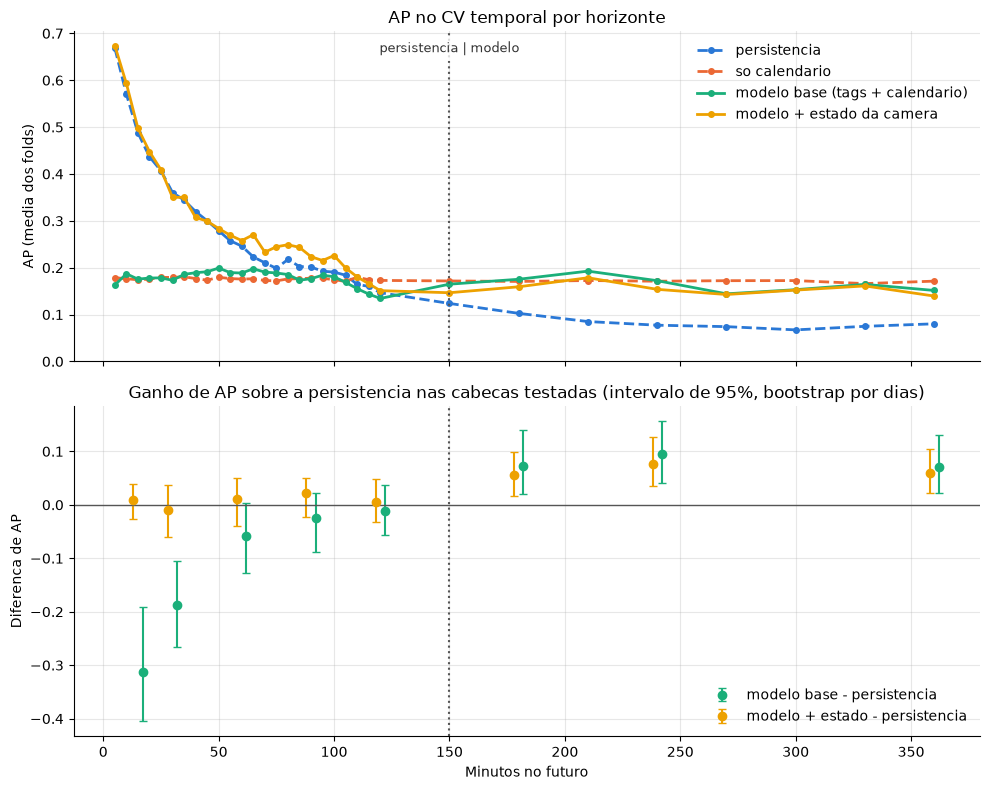

In [8]:
plot_horizons(tabela_cv, PATH_REPORTS / 'figures/horizontes_vs_persistencia.png', previsores)

## 3. Hold out (usado uma vez so, no final)

Treina no periodo de treino inteiro e mede o AP no hold out, com intervalo de 95% (bootstrap por dias)
da diferenca modelo - persistencia.

In [9]:
tabela_teste = holdout_ap(dx_treino, dx_holdout, CABECAS_POSSIVEIS, modelos)

 minutos  prevalencia_teste  ap_teste_persistencia  ap_teste_calendario  ic_inf_calendario_vs_persistencia  ic_sup_calendario_vs_persistencia  ap_teste_base  ic_inf_base_vs_persistencia  ic_sup_base_vs_persistencia  ap_teste_base_estado  ic_inf_base_estado_vs_persistencia  ic_sup_base_estado_vs_persistencia
      15              0.123                  0.721                0.504                             -0.390                             -0.049          0.525                       -0.299                       -0.055                 0.786                               0.024                               0.103
      30              0.124                  0.632                0.489                             -0.326                              0.037          0.493                       -0.264                       -0.023                 0.724                               0.040                               0.149
      60              0.124                  0.471                0.520  

In [10]:
#Table of the possible heads: AP in the CV (train) and in the hold out (test)
tabela_final = tabela_cv[['minutos', 'ap_persistencia', 'ap_base_estado']].merge(
    tabela_teste[['minutos', 'ap_teste_persistencia', 'ap_teste_base_estado',
                  'ic_inf_base_estado_vs_persistencia', 'ic_sup_base_estado_vs_persistencia']], on='minutos')
lista_previsor = []
lista_vence_calendario = []
for minutos in tabela_final['minutos']:
    lista_previsor.append(previsores[minutos])
    lista_vence_calendario.append(minutos in vence_calendario)
tabela_final['previsor'] = lista_previsor
tabela_final['modelo_vence_calendario'] = lista_vence_calendario
tabela_final

,minutos,ap_persistencia,ap_base_estado,ap_teste_persistencia,ap_teste_base_estado,ic_inf_base_estado_vs_persistencia,ic_sup_base_estado_vs_persistencia,previsor,modelo_vence_calendario
0,15,0.488016,0.497796,0.721,0.786,0.024,0.103,persistencia,True
1,30,0.360395,0.350063,0.632,0.724,0.040,0.149,persistencia,True
2,60,0.246087,0.257812,0.471,0.597,0.057,0.177,persistencia,False
3,90,0.201428,0.223525,0.368,0.489,0.069,0.165,persistencia,False
4,120,0.146676,0.151048,0.323,0.462,0.020,0.213,persistencia,False
5,180,0.102583,0.159301,0.266,0.400,-0.053,0.286,base_estado,False
6,240,0.077312,0.153811,0.240,0.351,-0.047,0.266,base_estado,False
7,360,0.080286,0.139503,0.164,0.462,0.094,0.404,base_estado,False


## 4. Report e constantes do config.py

In [11]:
info = {
    'Periodo de treino': str(dx_treino['Data'].min()) + ' ate ' + str(dx_treino['Data'].max()),
    'Hold out': str(dx_holdout['Data'].min()) + ' ate ' + str(dx_holdout['Data'].max()),
    'Dias removidos': DIAS_SUSPEITOS if REMOVER_DIAS_SUSPEITOS else 'nenhum',
    'Modelo': 'create_model() (LightGBM) do train.py',
    'Modelo vence o calendario (Holm)': vence_calendario,
    'Modelo vence persistencia e calendario (Holm)': vence_as_duas,
    'Features do modelo base': TAGS + CALENDARIO,
    'Estado da camera': ESTADO
}
save_horizon_report(tabela_cv, tabela_teste, previsores, info, PATH_REPORTS)

print('Copie para o config.py:')
print('PREVISOR_POR_CABECA =', previsores)

Report salvo em /home/jorgemetri/Desktop/git_repositories/ml_atmospheric_emission/reports/escolha_horizontes.md
Copie para o config.py:
PREVISOR_POR_CABECA = {15: 'persistencia', 30: 'persistencia', 60: 'persistencia', 90: 'persistencia', 120: 'persistencia', 180: 'base_estado', 240: 'base_estado', 360: 'base_estado'}
